# Time to recurrence, tumour proliferation and pathways

**Group project · gene expression · my implementation**, Seid Adem

[Notebook 01](01_recurrence_honest_evaluation.ipynb) found that gene expression predicts 3-year recurrence about as
well as the tumour's ISUP grade, and that the genes involved seem to track how aggressive the tumour is. This
notebook tests that idea directly and uses the data more fully:

1. **Survival analysis:** use *when* each patient's cancer progressed (or how long they were followed without
   progression), not just a yes/no at 3 years.
2. **A hypothesis-driven gene score:** if the expression signal is about fast-dividing tumour cells, a predefined
   **proliferation score** (the genes of Reactome's *Cell Cycle, Mitotic* pathway) should capture it, without
   selecting any gene using the outcome.
3. **Pathway analysis:** which biological processes differ between tumours that recurred and those that didn't?

> **In plain language: survival analysis.** Patients are followed for different lengths of time. Someone followed
> for 4 years without progression tells us "no event for at least 4 years", not "never": that is **censoring**.
> Survival methods use these partial observations properly. The **Kaplan–Meier curve** shows the share of patients
> still free of progression over time; a **Cox model** estimates a **hazard ratio** (how much a factor multiplies the
> risk of the event at any moment); the **concordance index (C)** is the survival version of AUC: how often the
> patient with the higher predicted risk progresses first. ([Lesson 7](../LESSONS.md))

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyreadr
import seaborn as sns
from IPython.display import display
from scipy.stats import mannwhitneyu, spearmanr
from sklearn.model_selection import StratifiedKFold
from statsmodels.duration.hazard_regression import PHReg
from statsmodels.duration.survfunc import SurvfuncRight, survdiff
from statsmodels.stats.multitest import multipletests

from dsls.ebi_api import EBIClient, reactome
from dsls.survival import concordance_index, gene_set_score

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
DATA = Path("../../../data/raw/gene_expression")
FIGURES = Path("figures")
RESULTS = Path("results")
SEED = 0


def km_step(ax, years, event, **kwargs):
    # Kaplan–Meier curve drawn to the group's last follow-up (statsmodels stores only the event times)
    sf = SurvfuncRight(years, event)
    ax.step(
        np.r_[0, sf.surv_times, years.max()], np.r_[1, sf.surv_prob, sf.surv_prob[-1]], where="post", **kwargs
    )


expr = pyreadr.read_r(DATA / "gene_expresion_prostate_cancer.RDS")[None]
pheno = pyreadr.read_r(DATA / "pheno_prostate_cancer.RDS")[None]
expr = expr.loc[:, expr.sum() > 0]
psa = pheno["PSA"].astype(float)
clin = pd.DataFrame({
    "years": pheno["PFI.time"] / 365.25,
    "event": pheno["PFI"].astype(int),
    "recurrence.3y": pheno["recurrence.3y"].astype(int),
    "ISUP grade": pheno["ISUP_group"].astype(int),
    "T stage": pheno["pathologic_T_simple"].astype(str).str[1].replace("a", np.nan).astype(float),
    "log2 PSA": np.log2(psa.fillna(1)).where(psa.notna()),
}, index=pheno.index)  # fmt: skip
print(f"{len(clin)} patients; {clin['event'].sum()} progression events ({clin['event'].mean():.0%}), "
      f"{((clin['event'] == 1) & (clin['recurrence.3y'] == 0)).sum()} of them after year 3; "
      f"median follow-up of patients without an event: {clin.loc[clin['event'] == 0, 'years'].median():.1f} years")  # fmt: skip

243 patients; 93 progression events (38%), 21 of them after year 3; median follow-up of patients without an event: 4.4 years


**The time-to-event view recovers information the 3-year label throws away:** 93 patients progressed, 21 of them
after year 3 (counted as "no recurrence" in notebook 01), and patients without an event were followed for a median
of 4.4 years. *(As prepared by the course, the data already exclude patients followed for less than 3 years without
an event, so all 243 here are the same patients as in notebook 01.)*

## 1 · Kaplan–Meier curves by ISUP grade

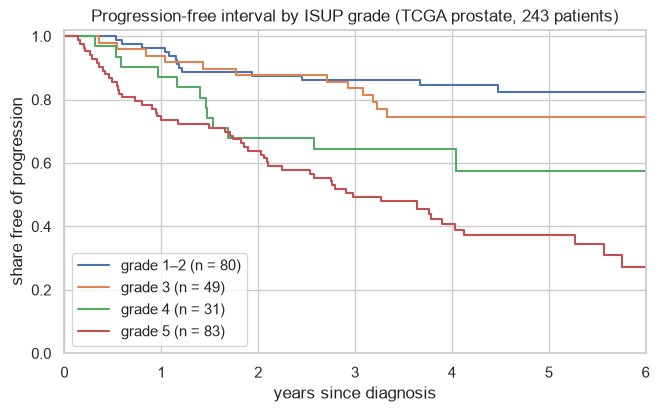

patients still followed after 5 years: 63
log-rank test across the four groups: chi² = 49.2, p = 1.2e-10


In [2]:
groups = clin["ISUP grade"].map({1: "grade 1–2", 2: "grade 1–2", 3: "grade 3", 4: "grade 4", 5: "grade 5"})
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for name in sorted(groups.unique()):
    sub = clin[groups == name]
    km_step(ax, sub["years"], sub["event"], label=f"{name} (n = {len(sub)})")
ax.set(xlabel="years since diagnosis", ylabel="share free of progression", ylim=(0, 1.02), xlim=(0, 6),
       title="Progression-free interval by ISUP grade (TCGA prostate, 243 patients)")  # fmt: skip
ax.legend()
fig.savefig(FIGURES / "03_kaplan_meier_grade.png", dpi=150, bbox_inches="tight")
plt.show()
chi2, p = survdiff(clin["years"], clin["event"], groups)
print(f"patients still followed after 5 years: {(clin['years'] > 5).sum()}")
print(f"log-rank test across the four groups: chi² = {chi2:.1f}, p = {p:.1e}")

**Grade separates the curves clearly** (log-rank p ≈ 10⁻¹⁰). After 3 years, roughly 85 % of grade 1–3 patients
are free of progression, compared with about half of grade 5 patients. Grades 1–2 and 3 are hard to tell apart.
Only 63 patients are followed beyond 5 years, so the right-hand ends of the curves rest on few patients
and their exact height shouldn't be over-read.

> **In plain language.** Each step down is a patient whose cancer progressed; the curve ends at that group's longest
> follow-up. The **log-rank test** asks whether the curves differ by more than chance.

## 2 · A predefined proliferation score

The genes come from **Reactome** (an EMBL-EBI/OICR pathway database), fetched through my cached API client. The score
for each tumour is the average, over those genes, of how far its expression is above or below the average tumour
(z-scores). Nothing about recurrence is used to build it.

Reactome release 98: 'Cell Cycle, Mitotic' (R-HSA-69278) has 522 human genes; 449 measured here
correlation of the proliferation score with ISUP grade: Spearman 0.56


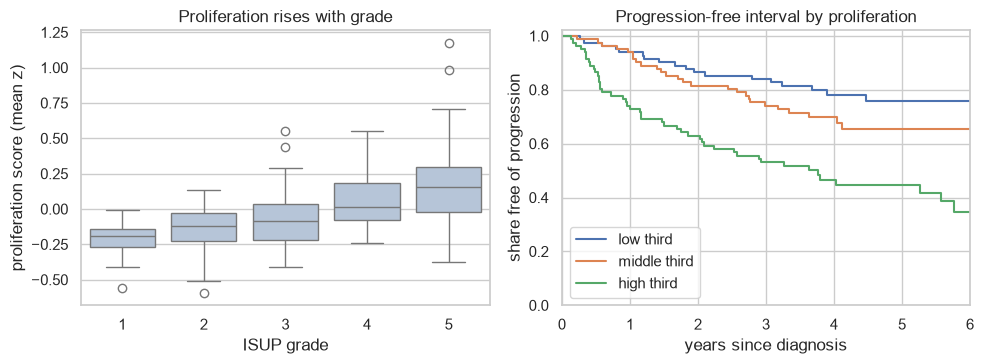

In [3]:
content = EBIClient("https://reactome.org/ContentService", "reactome-content")
version = content.get("data/database/version", accept="text/plain").content.decode()
entities = content.get_json("data/participants/R-HSA-69278/referenceEntities")
mitotic = sorted({e["geneName"][0] for e in entities if e.get("geneName")})
present = [g for g in mitotic if g in expr.columns]
print(
    f"Reactome release {version}: 'Cell Cycle, Mitotic' (R-HSA-69278) has {len(mitotic)} human genes; {len(present)} measured here"
)

clin["proliferation"] = gene_set_score(expr, mitotic)
rho = spearmanr(clin["proliferation"], clin["ISUP grade"]).statistic
print(f"correlation of the proliferation score with ISUP grade: Spearman {rho:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
sns.boxplot(x=clin["ISUP grade"], y=clin["proliferation"], color="lightsteelblue", ax=axes[0])
axes[0].set(ylabel="proliferation score (mean z)", title="Proliferation rises with grade")
tertile = pd.qcut(clin["proliferation"], 3, labels=["low", "middle", "high"])
for name in ("low", "middle", "high"):
    sub = clin[tertile == name]
    km_step(axes[1], sub["years"], sub["event"], label=f"{name} third")
axes[1].set(xlabel="years since diagnosis", ylabel="share free of progression", xlim=(0, 6), ylim=(0, 1.02),
            title="Progression-free interval by proliferation")  # fmt: skip
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURES / "04_proliferation_score.png", dpi=150, bbox_inches="tight")
plt.show()

**The proliferation score behaves as the hypothesis predicts:** it rises steadily with ISUP grade (Spearman 0.56),
and patients in the top third progress much sooner than those in the bottom two thirds. 449 of the pathway's 522
genes were measured here.

But the two left panels raise the key question: since proliferation and grade go together, is the score telling us
anything the pathologist doesn't?

## 3 · Cox models: does proliferation add to the grade?

Complete cases only (patients with T stage and PSA recorded), so every model is fitted on the same patients. Each
variable is standardised (hazard ratio per standard deviation), except ISUP grade (per grade step).

In [4]:
cc = clin.dropna(subset=["T stage", "log2 PSA"]).copy()
for col in ("T stage", "log2 PSA", "proliferation"):
    cc[col + " (SD)"] = (cc[col] - cc[col].mean()) / cc[col].std()


def cox(columns, data=cc):
    return PHReg(data["years"].to_numpy(), data[columns].to_numpy(), status=data["event"].to_numpy()).fit()


def hazard_table(columns):
    fit = cox(columns)
    ci = np.exp(fit.conf_int())
    return pd.DataFrame({"hazard ratio": np.exp(fit.params), "95 % low": ci[:, 0], "95 % high": ci[:, 1],
                         "p": fit.pvalues}, index=columns)  # fmt: skip


print(f"{len(cc)} complete cases, {cc['event'].sum()} events")
for cols in (["proliferation (SD)"], ["ISUP grade", "T stage (SD)", "log2 PSA (SD)"],
             ["ISUP grade", "T stage (SD)", "log2 PSA (SD)", "proliferation (SD)"]):  # fmt: skip
    print("\n" + " + ".join(cols))
    display(
        hazard_table(cols).style.format(
            {"hazard ratio": "{:.2f}", "95 % low": "{:.2f}", "95 % high": "{:.2f}", "p": "{:.1e}"}
        )
    )

232 complete cases, 88 events

proliferation (SD)


,hazard ratio,95 % low,95 % high,p
proliferation (SD),1.68,1.39,2.03,1.0e-07



ISUP grade + T stage (SD) + log2 PSA (SD)


,hazard ratio,95 % low,95 % high,p
ISUP grade,1.70,1.39,2.07,1.3e-07
T stage (SD),1.15,0.89,1.49,2.9e-01
log2 PSA (SD),1.05,0.86,1.28,6.5e-01



ISUP grade + T stage (SD) + log2 PSA (SD) + proliferation (SD)


,hazard ratio,95 % low,95 % high,p
ISUP grade,1.55,1.25,1.94,8.0e-05
T stage (SD),1.13,0.87,1.46,3.7e-01
log2 PSA (SD),1.07,0.87,1.32,5.1e-01
proliferation (SD),1.24,0.98,1.57,7.3e-02


In [5]:
# Control: is it proliferation, or would ANY average of this many genes do? Same model with random gene sets.
rng = np.random.default_rng(SEED)
base = ["ISUP grade", "T stage (SD)", "log2 PSA (SD)"]
z_real = cox(base + ["proliferation (SD)"]).tvalues[-1]
z_random = []
for _ in range(200):
    s = gene_set_score(expr, rng.choice(expr.columns, len(present), replace=False)).loc[cc.index]
    cc["random (SD)"] = (s - s.mean()) / s.std()
    z_random.append(cox(base + ["random (SD)"]).tvalues[-1])
z_random = np.array(z_random)
print(f"proliferation score: z = {z_real:.2f}; 200 random gene sets of the same size: median z = {np.median(z_random):.2f}, "
      f"{(z_random >= z_real).mean():.1%} reach z ≥ {z_real:.2f}")  # fmt: skip

proliferation score: z = 1.79; 200 random gene sets of the same size: median z = 0.84, 2.0% reach z ≥ 1.79


**On its own, proliferation is a strong risk factor; next to the grade, much of it disappears:**

* Alone: hazard ratio **1.68 per standard deviation** (95 % CI 1.39–2.03).
* ISUP grade is the only clinical variable that matters once all three are in the model (HR 1.70 per grade step);
  T stage and PSA add little.
* With the grade in the model, proliferation's hazard ratio falls to **1.24 (0.98–1.57, p = 0.07)**: a modest
  extra effect that this cohort can't confirm.

**The random gene-set control** shows why a control matters: averages of 449 *random* genes also carry some signal
(median z = 0.84, because many genes move with tumour aggressiveness), but only 2 % of 200 random sets reach the
proliferation score's z = 1.79. So the mitotic genes are more informative than an arbitrary gene average, and that
is still a weak extra signal on top of the grade.

> **In plain language.** A hazard ratio of 1.68 means that at any moment, a patient one standard deviation higher on
> the score has 68 % higher risk of progressing. When a second variable (grade) is added and the ratio shrinks, the
> two were largely measuring the same thing.

## 4 · Cross-validated concordance

The hazard ratios above describe the data. To ask whether the score **predicts**, fit each Cox model on 4/5 of the
patients and compute C on the other 1/5, repeated over 10 different splits (stratified by event).

In [6]:
models = {
    "ISUP grade": ["ISUP grade"],
    "clinical (grade + T + PSA)": base,
    "proliferation score": ["proliferation (SD)"],
    "clinical + proliferation": base + ["proliferation (SD)"],
}
rows = []
for r in range(10):
    for train, test in StratifiedKFold(n_splits=5, shuffle=True, random_state=r).split(cc, cc["event"]):
        tr, te = cc.iloc[train], cc.iloc[test]
        for name, cols in models.items():
            fit = cox(cols, tr)
            risk = te[cols].to_numpy() @ fit.params
            rows.append({"model": name, "repeat": r, "C": concordance_index(te["years"], te["event"], risk)})
cindex = pd.DataFrame(rows).groupby(["model", "repeat"])["C"].mean().unstack(0)[list(models)]
display(
    cindex.agg(["mean", "min", "max"])
    .T.round(3)
    .rename(columns={"min": "lowest repeat", "max": "highest repeat"})
)
gain = cindex["clinical + proliferation"] - cindex["clinical (grade + T + PSA)"]
print(
    f"adding proliferation to the clinical model: C {gain.mean():+.3f} on average; higher in {(gain > 0).sum()} of 10 repeats"
)

,mean,lowest repeat,highest repeat
model,,,
ISUP grade,0.683,0.677,0.688
clinical (grade + T + PSA),0.676,0.670,0.689
proliferation score,0.655,0.647,0.665
clinical + proliferation,0.690,0.680,0.697


adding proliferation to the clinical model: C +0.014 on average; higher in 10 of 10 repeats


**The same picture, measured as prediction on unseen patients:** the clinical model reaches C = 0.68, the
proliferation score alone 0.66, and the two together **0.69**. Adding proliferation raised C in **all 10 repeats**,
but by only **+0.014** on average: consistent, small. ISUP grade alone (0.683) is as good as grade + T stage + PSA
(0.676).

## 5 · Which pathways differ? Over-representation analysis

> **In plain language.** Take the genes most clearly higher (or lower) in tumours that progressed, and ask Reactome
> which pathways contain more of them than chance would predict. The **FDR** (false discovery rate) corrects for
> testing over a thousand pathways at once.

This step is **descriptive**: it uses all patients to describe the difference, not to build a predictor. Genes are
ranked by a Mann-Whitney test between patients with and without progression, and the 200 strongest in each
direction are submitted.

In [7]:
event = clin["event"].to_numpy().astype(bool)
p = mannwhitneyu(expr[event], expr[~event], axis=0).pvalue
up = expr[event].median() >= expr[~event].median()
ranked = pd.DataFrame(
    {"p": np.nan_to_num(p, nan=1.0), "higher with progression": up}, index=expr.columns
).sort_values("p")
ranked["FDR"] = multipletests(ranked["p"], method="fdr_bh")[1]
print(
    f"genes with FDR < 0.05: {(ranked['FDR'] < 0.05).sum():,} "
    f"({(ranked.loc[ranked['FDR'] < 0.05, 'higher with progression']).mean():.0%} higher with progression)"
)

client = reactome()
params = {"interactors": "false", "pageSize": 2000, "page": 1, "sortBy": "ENTITIES_PVALUE", "order": "ASC",
          "resource": "TOTAL", "species": "Homo sapiens", "includeDisease": "false"}  # fmt: skip
tables = {}
for direction, mask in (
    ("higher with progression", ranked["higher with progression"]),
    ("lower with progression", ~ranked["higher with progression"]),
):
    genes = ranked[mask].head(200).index
    result = client.post("identifiers/projection", "\n".join(genes), params).json()
    tables[direction] = pd.DataFrame([{
        "pathway": pw["name"], "genes found": pw["entities"]["found"], "pathway size": pw["entities"]["total"],
        "FDR": pw["entities"]["fdr"]} for pw in result["pathways"]])  # fmt: skip
    print(f"\n{direction}: 200 genes submitted, {result['identifiersNotFound']} not found in Reactome; "
          f"{len(result['pathways'])} pathways hit, {(tables[direction]['FDR'] < 0.05).sum()} with FDR < 0.05")  # fmt: skip
    display(tables[direction].head(10).style.format({"FDR": "{:.1e}"}).hide(axis="index"))
pd.concat(tables, names=["direction", "rank"]).to_csv(RESULTS / "reactome_enrichment.csv")

genes with FDR < 0.05: 2,889 (70% higher with progression)

higher with progression: 200 genes submitted, 91 not found in Reactome; 593 pathways hit, 12 with FDR < 0.05


pathway,genes found,pathway size,FDR
Cell Cycle,28,730,5.2e-04
"Cell Cycle, Mitotic",22,588,6.4e-03
Cell Cycle Checkpoints,14,279,7.4e-03
Separation of Sister Chromatids,11,182,7.8e-03
Mitotic Spindle Checkpoint,8,111,2.1e-02
Amplification of signal from unattached kinetochores via a MAD2 inhibitory signal,7,94,3.3e-02
Amplification of signal from the kinetochores,7,94,3.3e-02
Mitotic Anaphase,11,236,3.3e-02
Mitotic Metaphase and Anaphase,11,237,3.3e-02
Homology Directed Repair,8,133,3.5e-02



lower with progression: 200 genes submitted, 82 not found in Reactome; 505 pathways hit, 10 with FDR < 0.05


pathway,genes found,pathway size,FDR
XBP1(S) activates chaperone genes,8,95,2.1e-02
Metallothioneins bind metals,4,16,2.1e-02
Unfolded Protein Response (UPR),10,156,2.1e-02
IRE1alpha activates chaperones,8,101,2.1e-02
Noncanonical activation of NOTCH3,3,8,2.6e-02
Response to metal ions,4,21,2.6e-02
Cardiogenesis,5,39,2.6e-02
TGFBR3 PTM regulation,3,11,4.6e-02
Regulated proteolysis of p75NTR,3,12,4.7e-02
NOTCH4 Activation and Transmission of Signal to the Nucleus,3,12,4.7e-02


**Reactome independently points to cell division and DNA repair.** Without being told which pathways to look at,
the 200 genes most clearly higher in progressing tumours are enriched in **Cell Cycle**, **Cell Cycle, Mitotic**,
**Cell Cycle Checkpoints**, **Separation of Sister Chromatids**, the **Mitotic Spindle Checkpoint**, **Homology
Directed Repair** and the **Fanconi Anemia** DNA-repair pathway (12 pathways with FDR < 0.05). That matches the
stable genes in notebook 01 (*EME1*, *PARP2*, *DSN1*) and the proliferation score above.

The genes **lower** in progressing tumours point to the **unfolded protein response** (XBP1 / IRE1α chaperones),
**metallothioneins** and **NOTCH** signalling (10 pathways with FDR < 0.05), a weaker and less specific pattern.

**Caveats.** Over-representation analysis compares against all genes in Reactome, not only the genes measured
here; 91 and 82 of the 200 genes in each list aren't in Reactome at all; and the cut-off of 200 genes is a choice.
2,889 genes differ at FDR < 0.05, so the signal is broad, as notebook 01 found.

## Conclusions

1. **The expression signal for recurrence is largely proliferation.** A predefined mitotic gene score, built without
   looking at outcomes, predicts progression (HR 1.68 per SD), rises with grade, and Reactome finds cell-cycle and
   DNA-repair pathways among the genes higher in progressing tumours.
2. **Most of it is already captured by the ISUP grade.** Next to the grade, the score's hazard ratio drops to 1.24
   (p = 0.07), and adding it improves cross-validated concordance by +0.014 (0.676 → 0.690), consistently but
   modestly.
3. **Controls make the claim:** random gene sets show that "any average of genes" carries some signal; the mitotic
   genes beat 98 % of them.
4. **Survival analysis is the better framing:** it keeps the 21 late events and every patient's follow-up time that
   the 3-year label discards.

**Limitations.** One cohort (TCGA PRAD) with 88–93 events, so effects of the size seen here can't be confirmed or
ruled out; no external validation. Progression-free interval is a surrogate for clinical outcome. Cox proportional
hazards assumptions were not formally checked. The pathway step is descriptive and uses all patients.

*Data: TCGA PRAD as prepared by the course (UCSC Xena); Reactome release printed above
([CC BY 4.0](https://reactome.org/license)), cached in the git-ignored `data/raw/api_cache/`. Runtime: under a
minute.*